# Step 1 - Handling Missing Value

In [2]:
import numpy as np # mathematical calculation
import pandas as pd # Importing or exporting or data manipulation 
import matplotlib.pyplot as plt  # data visualization 
import seaborn as sns # data visualization with stats

In [4]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [8]:
df.shape

(891, 12)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [12]:
df.isnull().sum().sum()

866

In [14]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:
df.isnull().sum() / len(df)*100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [18]:
# Cabin - 77.1 % missing data found
# approach - drop this variable
df = df.drop(['Cabin'], axis=1)
df.isnull().sum() / len(df)*100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Embarked        0.224467
dtype: float64

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [22]:
df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [24]:
# handling categorical missing value - mode
df['Embarked'] = df['Embarked'].fillna('S')

In [26]:
df['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [28]:
df.isnull().sum() / len(df)*100

PassengerId     0.00000
Survived        0.00000
Pclass          0.00000
Name            0.00000
Sex             0.00000
Age            19.86532
SibSp           0.00000
Parch           0.00000
Ticket          0.00000
Fare            0.00000
Embarked        0.00000
dtype: float64

<Axes: ylabel='Age'>

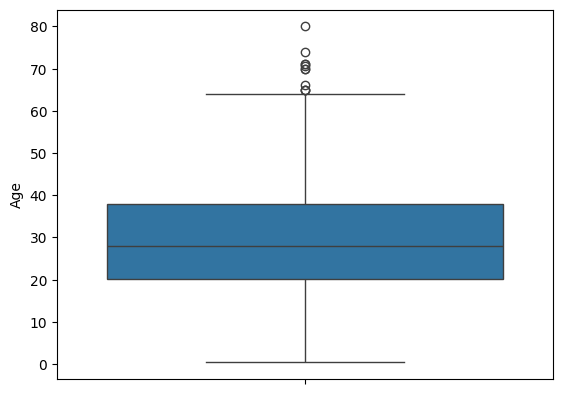

In [30]:
# handling numerical variable (age) missing data
# check outlier
sns.boxplot(y='Age', data=df)

In [32]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [34]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [36]:
df.isnull().sum() / len(df)*100

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64

In [38]:
df.isnull().sum().sum()

0

# Arbitrary-value-imputation

In [41]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [43]:
df1 = df.copy()

In [45]:
df2 = df.copy()

In [51]:
df1.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [49]:
df1 = df1.drop('Cabin', axis=1)

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer

In [59]:
x = df1.drop(columns = ['Survived'])
y = df1['Survived']

In [61]:
x.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [63]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [65]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25, random_state=0)

In [67]:
x_train['Age_999'] = x_train['Age'].fillna(99999)
x_train['Age_minus1'] = x_train['Age'].fillna(-1)

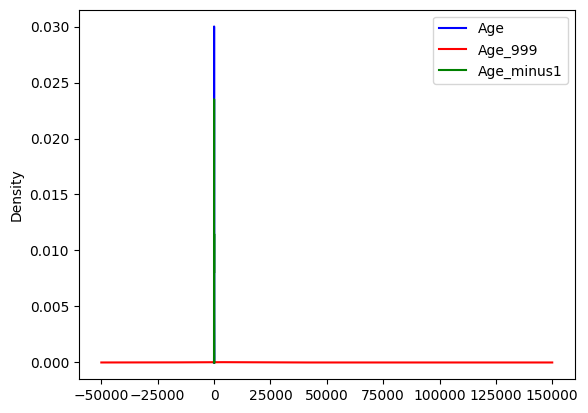

In [69]:
fig = plt.figure()
ax = fig.add_subplot(111)
x_train['Age'].plot(kind='kde', ax=ax, color='blue')
x_train['Age_999'].plot(kind='kde', ax=ax, color='red')
x_train['Age_minus1'].plot(kind='kde', ax=ax, color='green')

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [71]:
x_train.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Age_999,Age_minus1
105,106,3,"Mionoff, Mr. Stoytcho",male,28.0,0,0,349207,7.8958,S,28.0,28.0
68,69,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,3101281,7.9250,S,17.0,17.0
253,254,3,"Lobb, Mr. William Arthur",male,30.0,1,0,A/5. 3336,16.1000,S,30.0,30.0
320,321,3,"Dennis, Mr. Samuel",male,22.0,0,0,A/5 21172,7.2500,S,22.0,22.0
706,707,2,"Kelly, Mrs. Florence ""Fannie""",female,45.0,0,0,223596,13.5000,S,45.0,45.0


In [73]:
x_train.to_csv('x_train_testing.csv')

# KNN Imputation method

In [82]:
x_train.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age            133
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
Age_999          0
Age_minus1       0
dtype: int64

In [80]:
x_train['Embarked'] = x_train['Embarked'].fillna('S')

In [86]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 668 entries, 105 to 684
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  668 non-null    int64  
 1   Pclass       668 non-null    int64  
 2   Name         668 non-null    object 
 3   Sex          668 non-null    object 
 4   Age          535 non-null    float64
 5   SibSp        668 non-null    int64  
 6   Parch        668 non-null    int64  
 7   Ticket       668 non-null    object 
 8   Fare         668 non-null    float64
 9   Embarked     668 non-null    object 
 10  Age_999      668 non-null    float64
 11  Age_minus1   668 non-null    float64
dtypes: float64(4), int64(4), object(4)
memory usage: 67.8+ KB


In [108]:
x_train = np.where(x_train['Age_minus1']==-1,28,x_train['Age_minus1'])

In [110]:
x_train

array([28.  , 17.  , 30.  , 22.  , 45.  , 25.  , 18.  , 33.  , 24.  ,
       26.  , 22.  , 56.  , 28.  , 35.  ,  6.  , 41.  , 28.  , 28.  ,
       52.  , 32.  , 35.  , 18.  , 28.  , 28.  , 28.  , 28.  , 27.  ,
       22.  , 16.  , 49.  , 28.  , 16.  , 18.  , 28.  , 45.  ,  3.  ,
       70.5 , 28.  , 28.  , 34.5 , 40.  , 28.  , 27.  , 18.  , 28.  ,
       51.  , 49.  ,  1.  , 54.  , 28.  ,  8.  , 24.  , 20.  , 30.  ,
       24.  , 28.  , 28.  , 25.  , 28.  , 28.  , 48.  , 74.  , 23.  ,
       17.  , 28.  , 52.  , 28.  , 28.  , 34.  , 28.  , 34.  , 24.  ,
       29.  , 36.  , 61.  , 45.  , 34.  , 28.  , 21.  , 28.  ,  0.83,
       26.  , 28.  , 55.  ,  6.  , 50.  , 26.  , 34.  , 39.  , 30.  ,
       28.  , 22.  , 35.  , 42.  , 29.  , 28.  , 31.  , 28.  , 28.  ,
       41.  , 28.  , 46.  , 28.  , 50.  , 38.  , 11.  , 20.  , 35.  ,
       39.  ,  9.  , 19.  , 40.  , 38.  , 22.  , 65.  , 60.  , 47.  ,
       28.  , 51.  , 21.  , 27.  , 27.  , 49.  , 29.  , 16.  , 21.  ,
       47.  , 58.  ,

In [100]:
x_train1 = x_train[['Age','PassengerId','Pclass','Fare']]

In [102]:
x_train1

,Age,PassengerId,Pclass,Fare
105,28.0,106,3,7.8958
68,17.0,69,3,7.9250
253,30.0,254,3,16.1000
320,22.0,321,3,7.2500
706,45.0,707,2,13.5000
...,...,...,...,...
835,39.0,836,1,83.1583
192,19.0,193,3,7.8542
629,NaN,630,3,7.7333
559,36.0,560,3,17.4000


In [94]:
knn = KNNImputer(n_neighbors=5)
x_train_knn_imputation = knn.fit_transform(pd.DataFrame(x_train['Age']))

In [104]:
knn = KNNImputer(n_neighbors=5)
x_train_knn_imputation1 = knn.fit_transform(x_train1)

In [98]:
pd.DataFrame(x_train_knn_imputation).isnull().sum()

0    0
dtype: int64

In [106]:
pd.DataFrame(x_train_knn_imputation1).isnull().sum()

0    0
1    0
2    0
3    0
dtype: int64

# Encoding Method

### Approach 1 - Label Encoder
### Approach 2 - One Hot Encoder

In [113]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [115]:
df1['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [117]:
df1['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [119]:
df1 = pd.get_dummies(df1, columns=['Sex','Embarked'])
df1.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,True,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,True,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,True,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,False,True,False,False,True


In [121]:
# dummy variable
df1 = df1.drop(['Sex_male','Embarked_S'], axis=1)

In [123]:
df1.head(2)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Embarked_C,Embarked_Q
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,False,False,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,True,True,False


In [125]:
df1['Sex_female'] = np.where(df1['Sex_female']==False, 0,1)
df1['Embarked_C'] = np.where(df1['Embarked_C']==False, 0,1)
df1['Embarked_Q'] = np.where(df1['Embarked_Q']==False, 0,1)

In [127]:
df1.head(2)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Embarked_C,Embarked_Q
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,1,1,0


In [129]:
df1['Name'].nunique()

891

In [131]:
# Label encoder method
df1['Name'] = df1['Name'].astype('category').cat.codes

In [133]:
df1.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Embarked_C,Embarked_Q
0,1,0,3,108,22.0,1,0,A/5 21171,7.2500,0,0,0
1,2,1,1,190,38.0,1,0,PC 17599,71.2833,1,1,0
2,3,1,3,353,26.0,0,0,STON/O2. 3101282,7.9250,1,0,0
3,4,1,1,272,35.0,1,0,113803,53.1000,1,0,0
4,5,0,3,15,35.0,0,0,373450,8.0500,0,0,0


In [135]:
df1['Name'].nunique()

891

In [137]:
df1['Ticket'].unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012